
# Beyond Accuracy: Evaluating Machine-Learning Models

## Project Goal

The goal of this project is to compare two machine-learning models and investigate how well different evaluation metrics describe their performance.

## Research Question

How do Logistic Regression and Decision Tree compare in accuracy, precision, recall, F1-score, and types of prediction errors?

## Learning Objectives

- Understand the dataset and its features.
- Train and evaluate two classification models.
- Compare evaluation metrics across models.
- Examine prediction errors and identify differences in model performance.
- Explain the strengths and limitations of the results.



## Understanding the Machine-Learning Task

This project uses supervised machine learning.

Supervised learning means training a model with examples that already have known answers, called labels.

Our task is binary classification because the model predicts one of two categories:

- 0: No heart disease indicated in the dataset.
- 1: Heart disease indicated in the dataset.

We will compare Logistic Regression and Decision Tree classifiers, then evaluate their predictions using multiple metrics rather than accuracy alone.


In [36]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder




## Loading and Inspecting the Dataset

In [37]:
from ucimlrepo import fetch_ucirepo

# Fetch the Heart Disease dataset from UCI
heart_disease = fetch_ucirepo(id=45)

# Separate the input features and target
X = heart_disease.data.features
y = heart_disease.data.targets

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [38]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst five feature rows:")
print(X.head())

print("\nFirst five target rows:")
print(y.head())

Features shape: (303, 13)
Target shape: (303, 1)

First five feature rows:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   1       145   233    1        2      150      0      2.3      3   
1   67    1   4       160   286    0        2      108      1      1.5      2   
2   67    1   4       120   229    0        2      129      1      2.6      2   
3   37    1   3       130   250    0        0      187      0      3.5      3   
4   41    0   2       130   204    0        2      172      0      1.4      1   

    ca  thal  
0  0.0   6.0  
1  3.0   3.0  
2  2.0   7.0  
3  0.0   3.0  
4  0.0   3.0  

First five target rows:
   num
0    0
1    2
2    1
3    0
4    0


In [39]:
print("Missing values in each feature:")
print(X.isnull().sum())

print("\nFeature data types:")
print(X.dtypes)

print("\nOriginal target label counts:")
print(y["num"].value_counts(dropna=False).sort_index())

Missing values in each feature:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
dtype: int64

Feature data types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
dtype: object

Original target label counts:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [40]:
# Convert the original target into two classes
y_binary = (y["num"] > 0).astype(int)

print("Binary target counts:")
print(y_binary.value_counts().sort_index())

Binary target counts:
num
0    164
1    139
Name: count, dtype: int64


In [41]:
print(X.columns.tolist())

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


## Splitting the Dataset

In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_binary,
    test_size=0.2,
    random_state=42,
    stratify=y_binary
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (242, 13)
Testing features: (61, 13)
Training target: (242,)
Testing target: (61,)


## Data Preprocessing

In [43]:
# Numerical features
numeric_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak", "ca"
]

# Categorical features
categorical_features = [
    "sex", "cp", "fbs", "restecg", "exang", "slope", "thal"
]

print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))
print("Total features:", len(numeric_features) + len(categorical_features))

Number of numerical features: 6
Number of categorical features: 7
Total features: 13


In [44]:
# Calculate missing-value replacements using training data only
ca_median = X_train["ca"].median()
thal_mode = X_train["thal"].mode()[0]

print("Median for ca:", ca_median)
print("Most frequent value for thal:", thal_mode)

Median for ca: 0.0
Most frequent value for thal: 3.0


In [45]:
# Make copies of the training and testing data
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

# Fill missing values using replacements calculated from training data
X_train_clean["ca"] = X_train_clean["ca"].fillna(ca_median)
X_train_clean["thal"] = X_train_clean["thal"].fillna(thal_mode)

X_test_clean["ca"] = X_test_clean["ca"].fillna(ca_median)
X_test_clean["thal"] = X_test_clean["thal"].fillna(thal_mode)

In [46]:
print("Missing values in training data:", X_train_clean.isnull().sum().sum())
print("Missing values in testing data:", X_test_clean.isnull().sum().sum())

Missing values in training data: 0
Missing values in testing data: 0


In [47]:
# Check the minimum and maximum values of each numerical feature
print(X_train_clean[numeric_features].agg(["min", "max"]).to_string())

     age  trestbps  chol  thalach  oldpeak   ca
min   29        94   126       71      0.0  0.0
max   77       200   564      202      6.2  3.0


In [48]:
scaler = StandardScaler()

# Learn the scaling values from training data only
scaler.fit(X_train_clean[numeric_features])

# Apply the learned scaling to the training data
X_train_scaled = scaler.transform(X_train_clean[numeric_features])

print(X_train_scaled[:5])

[[-0.72948484 -0.39569185  0.4581394   0.70837124 -0.44544493 -0.68971531]
 [ 0.05016647 -0.05451337  0.23059762  0.22249537 -0.89162735 -0.68971531]
 [-0.06121229  0.0592128   0.72360482  0.3991775  -0.89162735  0.44573438]
 [-0.06121229 -1.30550115  1.12180294  0.26666591 -0.89162735 -0.68971531]
 [ 0.27292398  0.51411744 -0.16760051 -1.19096169 -0.71315438 -0.68971531]]


In [49]:
# Apply the same scaler to the testing data
X_test_scaled = scaler.transform(X_test_clean[numeric_features])

print(X_test_scaled[:5])

[[ 0.49568149  0.40039128  0.40125396  1.41509977 -0.89162735 -0.68971531]
 [ 1.27533279  1.65137906 -0.41410411 -0.52840369  1.16081179 -0.68971531]
 [-0.39534856 -0.05451337  0.11682672 -0.04252783 -0.44544493 -0.68971531]
 [-2.28878744 -0.73687034 -1.28634762  1.0617355  -0.89162735 -0.68971531]
 [-0.06121229  1.08274825 -0.33825685  0.6642007   0.5361564  -0.68971531]]


In [50]:
print(X_train_clean[categorical_features].head())

     sex  cp  fbs  restecg  exang  slope  thal
180    1   4    0        2      0      2   7.0
208    1   2    0        0      0      1   3.0
167    0   2    1        2      1      1   3.0
105    1   2    0        0      0      1   7.0
297    0   4    0        0      1      2   7.0


In [51]:
# Create the encoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
    dtype=int
)

# Learn the categorical values from training data only
encoder.fit(X_train_clean[categorical_features])

print("Encoder fitted successfully!")

Encoder fitted successfully!


In [52]:
# Get the names of the encoded columns
encoded_columns = encoder.get_feature_names_out(categorical_features)

# Transform the training categorical data
X_train_encoded_array = encoder.transform(
    X_train_clean[categorical_features]
)

# Convert training data into a DataFrame
X_train_encoded = pd.DataFrame(
    X_train_encoded_array,
    columns=encoded_columns,
    index=X_train_clean.index
)

# Transform the testing categorical data
X_test_encoded_array = encoder.transform(
    X_test_clean[categorical_features]
)

# Convert testing data into a DataFrame
X_test_encoded = pd.DataFrame(
    X_test_encoded_array,
    columns=encoded_columns,
    index=X_test_clean.index
)

print("Training encoded shape:", X_train_encoded.shape)
print("Testing encoded shape:", X_test_encoded.shape)

Training encoded shape: (242, 19)
Testing encoded shape: (61, 19)


In [53]:
# Convert the scaled numerical data into a DataFrame
X_train_numeric = pd.DataFrame(
    X_train_scaled,
    columns=numeric_features,
    index=X_train_clean.index
)

X_test_numeric = pd.DataFrame(
    X_test_scaled,
    columns=numeric_features,
    index=X_test_clean.index
)

In [54]:
# Combine numerical and encoded categorical features
X_train_final = pd.concat(
    [X_train_numeric, X_train_encoded],
    axis=1
)

X_test_final = pd.concat(
    [X_test_numeric, X_test_encoded],
    axis=1
)

print("Training data shape:", X_train_final.shape)
print("Testing data shape:", X_test_final.shape)

Training data shape: (242, 25)
Testing data shape: (61, 25)


## Logistic Regression

In [55]:
# Create the Logistic Regression model
model_lr = LogisticRegression(max_iter=1000)

# Train the model using the training data
model_lr.fit(X_train_final, y_train)
print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [56]:
# Make predictions using the testing features
y_pred_lr = model_lr.predict(X_test_final)


In [57]:
# Compare all actual labels with the model's predictions
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print(f"Logistic Regression Accuracy: {accuracy_lr:.2%}")

Logistic Regression Accuracy: 86.89%


In [58]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

print("Confusion Matrix:")
print(cm_lr)

Confusion Matrix:
[[27  6]
 [ 2 26]]


In [59]:
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)

print(f"Precision: {precision_lr:.2%}")
print(f"Recall:    {recall_lr:.2%}")
print(f"F1-score:  {f1_lr:.2%}")

Precision: 81.25%
Recall:    92.86%
F1-score:  86.67%


## Decision Tree

In [60]:
# Create the Decision Tree model
model_dt = DecisionTreeClassifier(random_state=42)

# Train the model
model_dt.fit(X_train_final, y_train)
print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [61]:
# Make predictions using the testing features
y_pred_dt = model_dt.predict(X_test_final)


In [62]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print(f"Decision Tree Accuracy: {accuracy_dt:.2%}")

Decision Tree Accuracy: 75.41%


In [63]:
# Evaluate Decision Tree predictions using a confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

print("Decision Tree Confusion Matrix:")
print(cm_dt)

Decision Tree Confusion Matrix:
[[22 11]
 [ 4 24]]


In [64]:
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)

print(f"Precision: {precision_dt:.2%}")
print(f"Recall:    {recall_dt:.2%}")
print(f"F1-score:  {f1_dt:.2%}")

Precision: 68.57%
Recall:    85.71%
F1-score:  76.19%


## Prediction Error Analysis

In [65]:
# Compare actual labels with both models' predictions
error_analysis = pd.DataFrame(index=y_test.index)

error_analysis["Actual"] = y_test
error_analysis["Logistic Regression"] = y_pred_lr
error_analysis["Decision Tree"] = y_pred_dt

print(error_analysis.head(10))

     Actual  Logistic Regression  Decision Tree
219       0                    0              1
271       0                    1              1
89        0                    0              0
101       0                    0              0
67        0                    0              0
244       0                    0              0
185       0                    0              1
233       0                    0              0
168       1                    1              1
197       0                    0              0


In [66]:
# Identify incorrect predictions made by each model
error_analysis["LR_wrong"] = (
    error_analysis["Actual"] != error_analysis["Logistic Regression"]
)

error_analysis["DT_wrong"] = (
    error_analysis["Actual"] != error_analysis["Decision Tree"]
)

print(error_analysis.head(10))

     Actual  Logistic Regression  Decision Tree  LR_wrong  DT_wrong
219       0                    0              1     False      True
271       0                    1              1      True      True
89        0                    0              0     False     False
101       0                    0              0     False     False
67        0                    0              0     False     False
244       0                    0              0     False     False
185       0                    0              1     False      True
233       0                    0              0     False     False
168       1                    1              1     False     False
197       0                    0              0     False     False


In [67]:
# Keep records where either model made a mistake
error_cases = error_analysis[
    error_analysis["LR_wrong"] | error_analysis["DT_wrong"]
]

print("Records with at least one error:", len(error_cases))
print(error_cases.to_string())

Records with at least one error: 17
     Actual  Logistic Regression  Decision Tree  LR_wrong  DT_wrong
219       0                    0              1     False      True
271       0                    1              1      True      True
185       0                    0              1     False      True
21        0                    0              1     False      True
23        1                    1              0     False      True
196       0                    1              1      True      True
33        0                    1              1      True      True
179       0                    1              0      True     False
3         0                    0              1     False      True
115       0                    0              1     False      True
292       1                    1              0     False      True
287       0                    1              1      True      True
66        1                    0              0      True      True
284       1 

In [68]:
# Count the errors made by each model
print("Logistic Regression errors:", error_analysis["LR_wrong"].sum())
print("Decision Tree errors:", error_analysis["DT_wrong"].sum())

# Count records where both models were wrong
both_wrong = (
    error_analysis["LR_wrong"] & error_analysis["DT_wrong"]
).sum()

print("Both models wrong:", both_wrong)

# Count records where only one model was wrong
lr_only_wrong = (
    error_analysis["LR_wrong"] & ~error_analysis["DT_wrong"]
).sum()

dt_only_wrong = (
    ~error_analysis["LR_wrong"] & error_analysis["DT_wrong"]
).sum()

print("Only Logistic Regression wrong:", lr_only_wrong)
print("Only Decision Tree wrong:", dt_only_wrong)

Logistic Regression errors: 8
Decision Tree errors: 15
Both models wrong: 6
Only Logistic Regression wrong: 2
Only Decision Tree wrong: 9


## Model Comparison

In [69]:
# Summarize the results of both models
model_results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [f"{accuracy_lr:.2%}", f"{accuracy_dt:.2%}"],
    "Precision": [f"{precision_lr:.2%}", f"{precision_dt:.2%}"],
    "Recall": [f"{recall_lr:.2%}", f"{recall_dt:.2%}"],
    "F1-score": [f"{f1_lr:.2%}", f"{f1_dt:.2%}"],
})

print(model_results.to_string(index=False))

              Model Accuracy Precision Recall F1-score
Logistic Regression   86.89%    81.25% 92.86%   86.67%
      Decision Tree   75.41%    68.57% 85.71%   76.19%


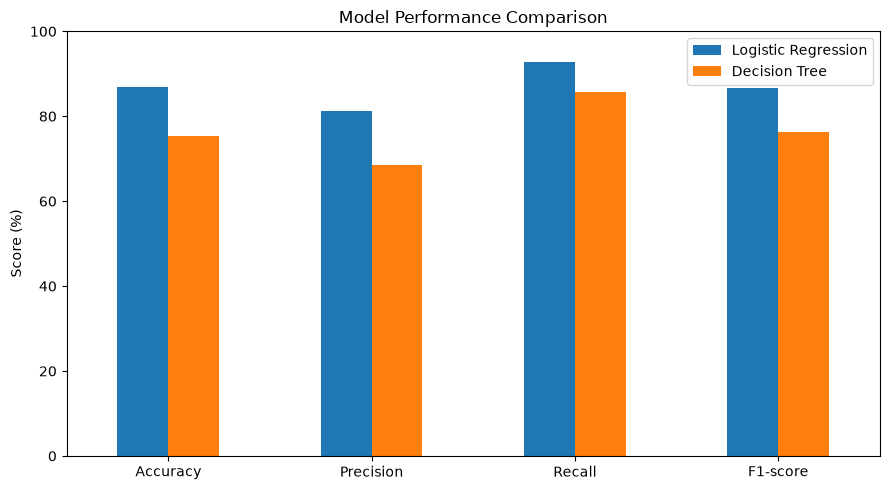

In [70]:
# Arrange the metrics as percentages for plotting
plot_data = pd.DataFrame({
    "Logistic Regression": [
        accuracy_lr, precision_lr, recall_lr, f1_lr
    ],
    "Decision Tree": [
        accuracy_dt, precision_dt, recall_dt, f1_dt
    ]
}, index=["Accuracy", "Precision", "Recall", "F1-score"]) * 100

# Create the bar chart
plot_data.plot(kind="bar", figsize=(9, 5))

plt.title("Model Performance Comparison")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

## Results and Interpretation

The two models were evaluated using the same 61 test records.

Logistic Regression achieved an accuracy of 86.89%, while the Decision Tree achieved 75.41%. Logistic Regression also achieved higher precision, recall, and F1-score on this test set.

The confusion matrices showed that Logistic Regression made 6 false-positive errors and 2 false-negative errors. The Decision Tree made 11 false-positive errors and 4 false-negative errors.

Logistic Regression correctly classified 53 out of 61 test records (86.89%), while the Decision Tree correctly classified 46 out of 61 (75.41%). In total, Logistic Regression made 8 incorrect predictions, compared with 15 for the Decision Tree. Both models made mistakes on 6 of the same records, while 2 records were misclassified only by Logistic Regression and 9 only by the Decision Tree.

These findings show that the models differed in both their overall performance and their prediction errors. However, the results come from a single train-test split and do not establish that Logistic Regression will always perform better on unseen data.

## Limitations

This experiment has several limitations:

- **Small dataset:** The dataset contains 303 records, of which 61 were used for testing. Results from such a small test set may not fully represent how the models perform on other data.

- **One train-test split:** We evaluated both models using one particular division of the dataset. A different division might produce different results. We did not use cross-validation to check how consistent the results were across different splits.

- **Simplified target:** The original target contained values from 0 to 4. We grouped all values above 0 into class 1 and kept 0 as class 0. This made the task a binary classification problem but removed distinctions between the original target categories.

- **Limited testing of model settings:** We used the initial settings for both models rather than systematically trying different settings. Other settings might produce different results.

- **Dataset limitations:** The dataset is historical and relatively small. Our findings should not automatically be assumed to apply to other populations or present-day healthcare settings.

- **Not a diagnostic tool:** This was an educational experiment in machine-learning evaluation. The models have not been clinically validated and should not be used to diagnose heart disease.

## Conclusion

This project compared Logistic Regression and Decision Tree classifiers using accuracy, precision, recall, F1-score, and prediction error analysis.

On the 61 test records, Logistic Regression achieved 86.89% accuracy, while the Decision Tree achieved 75.41%. Logistic Regression also obtained higher precision, recall, and F1-score on this test set.

The error analysis showed that Logistic Regression made 8 incorrect predictions, while the Decision Tree made 15. Both models made mistakes on 6 of the same records. Logistic Regression alone made mistakes on 2 records, while the Decision Tree alone made mistakes on 9 records.

These findings demonstrate how multiple evaluation metrics and error analysis can provide a more detailed understanding of model performance than accuracy alone.

However, the results are based on one train-test split of a relatively small dataset. Further evaluation would be needed to investigate how consistently the models perform on different data. This experiment is educational and does not establish that either model is suitable for medical diagnosis.